# 05A — HSV12 + HOG | KNN RGB224

Giữ cách duyệt KNN và phân tích kết quả của notebook 02. Mỗi nhánh đã được L2 riêng trước khi nối, không thêm trọng số và không L2 lại vector ghép. Chỉ dùng train/dev. Chạy Run All; sửa PROJECT_ROOT nếu cần. Chạy lại cập nhật kết quả của nhánh này. Đọc từng ảnh để trích lại HSV12 vì notebook 02 chưa xuất ma trận feature; không chạy lại lưới HSV12 riêng.

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import sys
from pathlib import Path
from itertools import product
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"
RESULTS_ROOT = PROJECT_ROOT / "src" / "KNN" / "results_224"
HSV_DIR = RESULTS_ROOT / "hsv12" / "features"
HOG_DIR = RESULTS_ROOT / "hog"
output_dir = RESULTS_ROOT / "hsv12_hog"
output_dir.mkdir(parents=True, exist_ok=True)

## 1. Đọc danh sách ảnh và nhãn

Dùng manifest HOG làm thứ tự gốc. HSV12 sẽ được trích theo đúng danh sách này để mỗi dòng hai khối thuộc cùng một ảnh. Các file kết quả HSV12 cũ được giữ nguyên; chỉ thêm thư mục feature.

In [2]:
train_manifest = pd.read_csv(HOG_DIR / "train_manifest.csv")
dev_manifest = pd.read_csv(HOG_DIR / "dev_manifest.csv")
y_train = np.load(HOG_DIR / "y_train.npy")
y_dev = np.load(HOG_DIR / "y_dev.npy")
print("Số ảnh train:", len(train_manifest))
print("Số ảnh dev:", len(dev_manifest))

Số ảnh train: 12494
Số ảnh dev: 1564


## 2. Trích lại HSV12

Cùng RGB224 bilinear, miền giá trị và chuẩn hóa L2 như notebook 02. Mỗi vòng chỉ giữ một ảnh; không nạp toàn bộ ảnh gốc. Không chia pixel cho 255.

In [3]:
HSV_BINS = 12

def extract_hsv_histogram(image, bins=12):
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist(
        [hsv_image], [0, 1, 2], None,
        [bins, bins, bins], [0, 180, 0, 256, 0, 256]
    )
    return cv2.normalize(hist, hist).flatten()


def extract_hsv_from_manifest(manifest):
    features = np.empty((len(manifest), HSV_BINS ** 3), dtype=np.float32)
    for i, relative_path in enumerate(manifest["relative_path"]):
        image = cv2.imread(str(DATA_ROOT / relative_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_LINEAR)
        features[i] = extract_hsv_histogram(image, bins=HSV_BINS)
        del image
    return features


X_train_hsv = extract_hsv_from_manifest(train_manifest)
X_dev_hsv = extract_hsv_from_manifest(dev_manifest)

HSV_DIR.mkdir(parents=True, exist_ok=True)
np.save(HSV_DIR / "X_train.npy", X_train_hsv)
np.save(HSV_DIR / "X_dev.npy", X_dev_hsv)
np.save(HSV_DIR / "y_train.npy", y_train)
np.save(HSV_DIR / "y_dev.npy", y_dev)
train_manifest.to_csv(HSV_DIR / "train_manifest.csv", index=False)
dev_manifest.to_csv(HSV_DIR / "dev_manifest.csv", index=False)
print("HSV12 train/dev:", X_train_hsv.shape, X_dev_hsv.shape)

HSV12 train/dev: (12494, 1728) (1564, 1728)


## 3. Ghép HSV12 với HOG không PCA

Đọc X_train.npy/X_dev.npy của HOG đã L2, không dùng file before_l2. Ghép theo thứ tự HSV12 trước, HOG sau. 1.728 + 6.084 = 7.812 chiều.

In [4]:
X_train_hog = np.load(HOG_DIR / "X_train.npy")
X_dev_hog = np.load(HOG_DIR / "X_dev.npy")

In [5]:
X_train_fusion = np.concatenate([X_train_hsv, X_train_hog], axis=1)
X_dev_fusion = np.concatenate([X_dev_hsv, X_dev_hog], axis=1)
del X_train_hsv, X_dev_hsv, X_train_hog, X_dev_hog

np.save(output_dir / "X_train.npy", X_train_fusion)
np.save(output_dir / "X_dev.npy", X_dev_fusion)
np.save(output_dir / "y_train.npy", y_train)
np.save(output_dir / "y_dev.npy", y_dev)
train_manifest.to_csv(output_dir / "train_manifest.csv", index=False)
dev_manifest.to_csv(output_dir / "dev_manifest.csv", index=False)

print("Train:", X_train_fusion.shape, y_train.shape)
print("Dev:", X_dev_fusion.shape, y_dev.shape)
print("Dtype:", X_train_fusion.dtype)
print("Giá trị hữu hạn:", np.isfinite(X_train_fusion).all(), np.isfinite(X_dev_fusion).all())
print("Độ dài vector ghép gần căn 2:",
      np.allclose(np.linalg.norm(X_train_fusion, axis=1), np.sqrt(2), atol=1e-5),
      np.allclose(np.linalg.norm(X_dev_fusion, axis=1), np.sqrt(2), atol=1e-5))

Train: (12494, 7812) (12494,)
Dev: (1564, 7812) (1564,)
Dtype: float32
Giá trị hữu hạn: True True
Độ dài vector ghép gần căn 2: True True


## 4. Tìm tham số KNN trên dev

Giống notebook 02: k=1..10 × uniform/distance × Euclidean = 20 cấu hình. Chọn Macro-F1 cao nhất, hòa thì MAE thấp hơn, vẫn hòa thì thứ tự thử. So sánh số chưa làm tròn.

In [6]:
n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = ["euclidean"]

results_fusion = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_fusion, y_train)
    y_pred = knn.predict(X_dev_fusion)
    scores = evaluate_classification(y_dev, y_pred)

    results_fusion.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_fusion = (
    pd.DataFrame(results_fusion)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("Tổng số cấu hình:", len(df_results_fusion))
display(df_results_fusion.head(10))

Tổng số cấu hình: 20


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,6,distance,euclidean,0.731995,62071.611253,0.729540
1,4,distance,euclidean,0.731825,61093.350384,0.730179
2,5,distance,euclidean,0.729826,62026.854220,0.728261
3,1,uniform,euclidean,0.726608,58740.409207,0.726343
4,1,distance,euclidean,0.726608,58740.409207,0.726343
5,2,distance,euclidean,0.726608,58740.409207,0.726343
6,7,distance,euclidean,0.724432,62563.938619,0.720588
7,3,distance,euclidean,0.724403,61879.795396,0.723785
8,5,uniform,euclidean,0.721969,63759.590793,0.721228
9,8,distance,euclidean,0.716813,64379.795396,0.713555


In [7]:
# Chọn cấu hình tốt nhất và so sánh các khoảng cách
best_fusion = df_results_fusion.iloc[0]
print("Cấu hình HSV12 + HOG tốt nhất trên DEV:")
print(best_fusion.to_string())

best_by_metric_fusion = (
    df_results_fusion
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)

display(best_by_metric_fusion[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình HSV12 + HOG tốt nhất trên DEV:
k                      6
weights         distance
metric         euclidean
macro_f1        0.731995
mae_vnd     62071.611253
accuracy         0.72954


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,euclidean,6,distance,0.731995,62071.611253,0.72954


## 5. Confusion matrix và kết quả từng lớp

In [8]:
# Đọc trực tiếp tham số từ Grid Search (không hard-code như ví dụ RGB cũ)
best_knn_fusion = KNeighborsClassifier(
    n_neighbors=int(best_fusion["k"]),
    weights=str(best_fusion["weights"]),
    metric=str(best_fusion["metric"]),
    algorithm="brute"
)
best_knn_fusion.fit(X_train_fusion, y_train)
y_dev_pred_fusion = best_knn_fusion.predict(X_dev_fusion)

fusion_scores = evaluate_classification(y_dev, y_dev_pred_fusion)
print("DEV Accuracy:", fusion_scores["accuracy"])
print("DEV Macro-F1:", fusion_scores["macro_f1"])
print("DEV MAE_VND:", fusion_scores["mae_vnd"])


DEV Accuracy: 0.729539641943734
DEV Macro-F1: 0.7319949792405468
DEV MAE_VND: 62071.611253196934


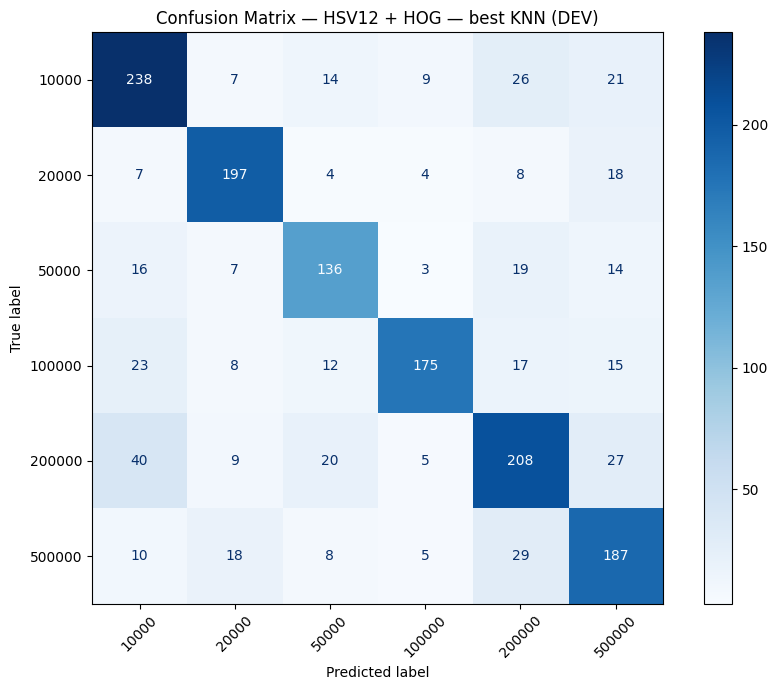

In [9]:
labels = np.sort(np.unique(y_train))
cm_fusion = confusion_matrix(y_dev, y_dev_pred_fusion, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_fusion, display_labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — HSV12 + HOG — best KNN (DEV)")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix_dev.png", dpi=150)
plt.show()

In [10]:
# Precision / Recall / F1 theo mệnh giá — đọc được lớp nào mạnh/yếu
report_fusion = classification_report(
    y_dev, y_dev_pred_fusion,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_fusion = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_fusion[str(label)]["precision"],
        "recall": report_fusion[str(label)]["recall"],
        "f1": report_fusion[str(label)]["f1-score"],
        "support": int(report_fusion[str(label)]["support"]),
    }
    for label in labels
])
display(per_class_fusion)

print(f"Số ảnh đúng: {np.trace(cm_fusion)}/{cm_fusion.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.712575,0.755556,0.733436,315
1,20000,0.800813,0.827731,0.814050,238
2,50000,0.701031,0.697436,0.699229,195
3,100000,0.870647,0.700000,0.776053,250
4,200000,0.677524,0.673139,0.675325,309
5,500000,0.663121,0.727626,0.693878,257


Số ảnh đúng: 1141/1564


In [11]:
# Những cặp mệnh giá có tổng số nhầm lẫn hai chiều lớn nhất
error_pairs_fusion = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_fusion[i, j])
        errors_ji = int(cm_fusion[j, i])
        error_pairs_fusion.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_fusion = (
    pd.DataFrame(error_pairs_fusion)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:")
display(df_error_pairs_fusion.head(5))

Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
3,10000 ↔ 200000,26,40,66
14,200000 ↔ 500000,27,29,56
10,50000 ↔ 200000,19,20,39
8,20000 ↔ 500000,18,18,36
2,10000 ↔ 100000,9,23,32


## 6. Lưu kết quả

Giữ dự đoán từng ảnh và bảng kết quả để so sánh với các nhánh riêng. Không chọn tham số bằng test. Chưa khóa cấu hình KNN cuối ở notebook này.

In [12]:
feature_name = "HSV12 + HOG"
summary_fusion = pd.DataFrame([{
    "feature": feature_name, "feature_dim": X_train_fusion.shape[1],
    "k": int(best_fusion["k"]), "weights": str(best_fusion["weights"]),
    "metric": str(best_fusion["metric"]),
    "macro_f1": fusion_scores["macro_f1"], "accuracy": fusion_scores["accuracy"],
    "mae_vnd": fusion_scores["mae_vnd"],
}])
df_results_fusion.to_csv(output_dir / "fusion_knn_grid_dev.csv", index=False)
summary_fusion.to_csv(output_dir / "fusion_best_dev.csv", index=False)
per_class_fusion.to_csv(output_dir / "per_class_dev.csv", index=False)
pd.DataFrame(cm_fusion, index=labels, columns=labels).to_csv(output_dir / "confusion_matrix_dev.csv")
df_error_pairs_fusion.to_csv(output_dir / "error_pairs_bidirectional_dev.csv", index=False)
predictions = dev_manifest[["relative_path"]].copy()
predictions["y_true_vnd"] = y_dev
predictions["y_pred_vnd"] = y_dev_pred_fusion
predictions.to_csv(output_dir / "predictions_dev.csv", index=False)
(output_dir / "metrics_dev.json").write_text(json.dumps(fusion_scores, indent=2), encoding="utf-8")

config = {
    "feature": feature_name, "image": "RGB uint8 224x224, OpenCV INTER_LINEAR",
    "hsv": "joint HSV12, OpenCV ranges, L2", "hog_source": HOG_DIR.name,
    "pca_on_hog": False, "branch_norm": "L2 separately", "concatenation_order": ["HSV12", "HOG branch"],
    "normalization_after_concat": False, "extra_branch_weights": False,
    "feature_dtype": "float32", "feature_dim": X_train_fusion.shape[1],
    "k_options": list(n_neighbors_options), "weight_options": weight_options,
    "metric_options": metric_options, "algorithm": "brute",
    "best_k": int(best_fusion["k"]), "best_weights": str(best_fusion["weights"]),
    "best_metric": str(best_fusion["metric"]),
}
(output_dir / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Đã lưu vào:", output_dir)
display(summary_fusion)

Đã lưu vào: C:\CS231\src\KNN\results_224\hsv12_hog


,feature,feature_dim,k,weights,metric,macro_f1,accuracy,mae_vnd
0,HSV12 + HOG,7812,6,distance,euclidean,0.731995,0.72954,62071.611253


## 7. So sánh với các nhánh riêng

Bảng đầu so cấu hình tốt nhất mỗi phương án. Bảng sau giữ k=1, uniform, Euclidean để đối chiếu khi bộ phân loại cố định. Các nhánh thêm sau không mặc định phải tốt hơn; chưa chọn kết quả cuối toàn nhánh KNN.

In [13]:
hsv_best = pd.read_csv(RESULTS_ROOT / "hsv12" / "hsv12_best_dev.csv")
hog_best = pd.read_csv(HOG_DIR / (HOG_DIR.name + "_best_dev.csv"))
comparison = pd.concat([hsv_best, hog_best, summary_fusion], ignore_index=True)
comparison.to_csv(output_dir / "comparison_best_dev.csv", index=False)
display(comparison[["feature", "feature_dim", "k", "weights", "accuracy", "macro_f1", "mae_vnd"]])

hsv_grid = pd.read_csv(RESULTS_ROOT / "hsv12" / "hsv12_knn_grid_dev.csv")
hog_grid = pd.read_csv(HOG_DIR / (HOG_DIR.name + "_knn_grid_dev.csv"))
reference_rows = []
for name, grid in [("HSV12", hsv_grid), (HOG_DIR.name, hog_grid), (feature_name, df_results_fusion)]:
    row = grid.loc[(grid["k"] == 1) & (grid["weights"] == "uniform")].iloc[0].to_dict()
    row["feature"] = name
    reference_rows.append(row)
reference_comparison = pd.DataFrame(reference_rows)
reference_comparison.to_csv(output_dir / "comparison_reference_dev.csv", index=False)
display(reference_comparison[["feature", "k", "weights", "metric", "accuracy", "macro_f1", "mae_vnd"]])

,feature,feature_dim,k,weights,accuracy,macro_f1,mae_vnd
0,Histogram HSV 12x12x12,1728,1,uniform,0.796036,0.798307,46585.677749
1,HOG RGB224 - no PCA,6084,1,uniform,0.390665,0.390748,116234.015345
2,HSV12 + HOG,7812,6,distance,0.729540,0.731995,62071.611253


,feature,k,weights,metric,accuracy,macro_f1,mae_vnd
0,HSV12,1,uniform,euclidean,0.796036,0.798307,46585.677749
1,hog,1,uniform,euclidean,0.390665,0.390748,116234.015345
2,HSV12 + HOG,1,uniform,euclidean,0.726343,0.726608,58740.409207
